# Step 5 — Comparison of friend and taste communities

*Author: Jose. Code: `src/comparison.py` (functions, tested in `tests/test_comparison.py`); this notebook runs them and explains the choices.*

**Question.** Are friend communities also taste communities? Step 2 built a **friend** partition and step 3 a **taste** partition of the *same* 7,947 Philadelphia users. Here we measure how much they agree and whether the agreement is more than chance.

**The trap this step has to avoid.** Step 2 found that friend communities line up with *when* their members were active on Yelp (NMI 0.22 against 0.001 by chance). Two friends active in the same years can only review restaurants that were open then, so they look alike for reasons that have nothing to do with taste. Every test below is therefore run twice: once ignoring the period, and once **controlling for it** (shuffling only among users of the same period bin). The second one is the one that counts.

**What is computed**

| Block | Question it answers |
|---|---|
| 1. Partition agreement | NMI, ARI (and AMI) between the friend and the taste partition: chosen runs, and the 20 × 20 saved runs of each |
| 2. Noise ceiling | How much two runs of the *same* method agree with each other (the most one can ask of a comparison) |
| 3. Period baselines | NMI/ARI of each partition against the period bins |
| 4. Permutation test (partition level) | Is the agreement above what the period alone produces? |
| 5. Sensitivity | Do the isolated users and the tiny communities change the answer? |
| 6. Pair level | Do friend pairs share a taste community / liked items more than other pairs? |
| 7. Restaurants vs categories | Does the answer depend on how taste is represented? |

## How to run

1. Raw Yelp files in `data/raw/` (original names), then run, in this order: `01_data_cleaning.ipynb` → `02_friend_communities.ipynb` → `03_taste_communities.ipynb`. `data/` is not in git, so every team member regenerates these files locally.
2. Run this notebook (*Run All*) from the repository root or from `notebooks/`. About 6–10 minutes on a laptop. The same analysis can be run from the command line with `python src/comparison.py`.
3. Inputs read (nothing is recomputed from the raw data): `data/processed/philadelphia_pa_friend_communities*.parquet`, `philadelphia_pa_friend_edges.parquet`, `philadelphia_pa_{reviews,businesses,users}.parquet` and `data/results/taste_communities*.parquet`.
4. Outputs: `data/results/comparison_*.json/csv` (not in git) and `figures/05_*.png`.

Dependencies: `pip install numpy pandas scipy scikit-learn matplotlib pyarrow networkx` (see `requirements.txt`).

## 0. Setup

All parameters are in this cell.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# make src/ importable whether Jupyter was started from the repo root or from notebooks/
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT / "src"))
import comparison as C

# --- parameters -----------------------------------------------------------
SEED = 42
N_PERM_MAIN = 10_000    # permutations for the chosen pair of partitions (smallest possible p = 1/10,001)
N_PERM_GRID = 1_000     # permutations for each of the 20 x 20 grid cells
N_PERM_OTHER = 1_000    # period baselines, sensitivity variants, friend-pair share
N_PERM_PAIRS = 1_000    # friend-pair Jaccard test (the report uses P = 1000)
STRICT = True           # stop if the regenerated partitions differ from the numbers in the report

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
print("project root:", ROOT)

project root: /home/juse/02807_computational_tools/Computational-tools-4-datasciense


## 1. Inputs and sanity check

`load_inputs` reads the files of steps 1–3 and puts them on the same users. **Sanity check:** each team member regenerates the data, so a different library version could change a Louvain run without anyone noticing. `check_against_report` compares what we loaded with what the report says (7,947 users; 51 friend communities; 17 category and 19 restaurant taste communities in the chosen runs, which include the singleton communities of the users isolated in the taste graph). With `STRICT = True` the notebook stops if anything differs.

In [2]:
inp = C.load_inputs(ROOT)
sanity = C.check_against_report(inp, STRICT)
print("found:", sanity["found"])
print("matches the report:", sanity["ok"])

print(f"\n{len(inp.edge_u):,} friend pairs; {inp.friend_seeds.shape[1]} friend runs; "
      f"{ {v: inp.taste_seeds[v].shape[1] for v in C.VERSIONS} } taste runs")
pd.DataFrame({"users": np.bincount(inp.period)}, index=inp.period_labels).T

found: {'n_users': 7947, 'friend_communities': 51, 'taste_communities': {'category': 17, 'business': 19}, 'n_isolated_users': {'category': 8, 'business': 6}, 'n_friend_pairs': 67622, 'n_friend_runs': 20, 'n_taste_runs': {'category': 20, 'business': 20}}
matches the report: True

67,622 friend pairs; 20 friend runs; {'category': 20, 'business': 20} taste runs


,<=2010,2011-13,2014-16,>=2017
users,1060,1841,2329,2717


In [3]:
# community sizes of the chosen partitions (largest first)
def sizes(x, k=8):
    s = pd.Series(x).value_counts().to_numpy()
    return f"{len(s)} communities; largest {', '.join(map(str, s[:k]))} ..."

print("friends:          ", sizes(inp.friend_main))
for v in C.VERSIONS:
    print(f"taste, {v:<9}:", sizes(inp.taste_main[v]), f"| isolated users: {int(inp.isolated[v].sum())}")

friends:           51 communities; largest 2460, 1667, 1607, 818, 661, 196, 123, 98 ...
taste, category : 17 communities; largest 1539, 1303, 1248, 1163, 1087, 855, 366, 324 ... | isolated users: 8
taste, business : 19 communities; largest 1047, 874, 820, 798, 715, 657, 638, 629 ... | isolated users: 6


## 2. The measures

* **NMI** (normalised mutual information): how much knowing a user's friend community tells us about their taste community; 0 = nothing, 1 = identical partitions. Arithmetic-mean normalisation (the scikit-learn default). With many small clusters NMI is **inflated by chance**, which is why it is never read without its null.
* **ARI** (adjusted Rand index): fraction of user pairs on which the two partitions agree, corrected for chance; 0 = random, 1 = identical. Dominated by the big communities (5 friend communities hold 91 % of the users).
* **AMI**: NMI corrected for chance with the exact expected value; reported for the headline pairs only (it is too slow for thousands of permutations).
* Community labels are arbitrary: only the grouping matters, never the label numbers.

**Noise ceiling.** Louvain runs on different seeds agree only moderately (ARI 0.54 between friend runs, about 0.32 between taste runs). Two partitions cannot agree with each other more than each agrees with itself, so the run-to-run agreement is shown next to every result.

**Permutation test, controlling for the period.** The friend partition stays fixed; taste labels are shuffled **among users of the same period bin** (≤ 2010, 2011–13, 2014–16, ≥ 2017, the median year of each user's reviews). That keeps the link between taste and period but destroys the link between taste and friends, so the null distribution answers: *how much agreement does the period alone produce?* p = (1 + #{null ≥ observed}) / (1 + P). The **plain** shuffle (all users together) is reported too, only to show how much the control matters.

First, our NMI/ARI against scikit-learn on the chosen partitions (raises an error if they differ):

In [4]:
for v in C.VERSIONS:
    view = C.make_view(inp, v)
    print(v, {k: round(x, 6) for k, x in C.verify_against_sklearn(view.f_main, view.t_main).items()})

category {'nmi': 0.041685, 'ari': 0.013278, 'sklearn_nmi': 0.041685, 'sklearn_ari': 0.013278}
business {'nmi': 0.077981, 'ari': 0.037264, 'sklearn_nmi': 0.077981, 'sklearn_ari': 0.037264}


## 3. Partition level: category taste (main) and restaurant taste

For each taste version `analyse_version` runs: the chosen pair with `N_PERM_MAIN` permutations, the 20 × 20 grid of saved runs (each cell with its own within-period null), the noise ceilings, the period baselines, the sensitivity variants and the friend-pair share. The category version is the main one (Cesi's recommendation: restaurant sets overlap partly because friends went together or were active in the same years).

Users with no similar pair in the taste graph (6–8 users) are singleton "communities" and are **excluded** from the main analysis; the sensitivity block shows the effect of including them.

In [5]:
res_cat, tab_cat = C.analyse_version(inp, "category", N_PERM_MAIN, N_PERM_GRID, N_PERM_OTHER, SEED)

[category] 7,939 users (8 isolated excluded), 67,591 friend pairs


[category] chosen partitions, 10,000 permutations


[category] 20 x 20 grid, 1,000 permutations


    grid permutations 250/1000


    grid permutations 500/1000


    grid permutations 750/1000


... (2 outputs left out)

    edge-share permutations 250/1000


    edge-share permutations 500/1000


    edge-share permutations 750/1000


    edge-share permutations 1000/1000


In [6]:
res_bus, tab_bus = C.analyse_version(inp, "business", N_PERM_MAIN, N_PERM_GRID, N_PERM_OTHER, SEED)

[business] 7,941 users (6 isolated excluded), 67,595 friend pairs


[business] chosen partitions, 10,000 permutations


[business] 20 x 20 grid, 1,000 permutations


    grid permutations 250/1000


    grid permutations 500/1000


    grid permutations 750/1000


... (2 outputs left out)

    edge-share permutations 250/1000


    edge-share permutations 500/1000


    edge-share permutations 750/1000


    edge-share permutations 1000/1000


In [7]:
results = {"parameters": {"n_perm_main": N_PERM_MAIN, "n_perm_grid": N_PERM_GRID, "n_perm_other": N_PERM_OTHER,
                          "n_perm_pairs": N_PERM_PAIRS, "seed": SEED, "min_community": C.MIN_COMMUNITY,
                          "period_bins": inp.period_labels},
           "sanity": sanity, "versions": {"category": res_cat, "business": res_bus}}
tables = {"category": tab_cat, "business": tab_bus}

### 3.1 Chosen partitions against both null models

In [8]:
C.main_table(results).round(4)

,taste version,measure,observed,"chance, shuffled within period",excess,z,p (within period),"chance, plain shuffle",p (plain shuffle)
0,category taste,NMI,0.0417,0.0214,0.0203,19.8296,0.0001,0.0112,0.0001
1,category taste,ARI,0.0133,0.0054,0.0079,9.3799,0.0001,-0.0000,0.0001
2,category taste,NMI inside period bins,0.0475,0.0251,0.0224,23.6732,0.0001,NaN,NaN
3,category taste,ARI inside period bins,0.0072,-0.0000,0.0072,6.5214,0.0001,NaN,NaN
4,category taste,AMI,0.0308,NaN,NaN,NaN,NaN,NaN,NaN
5,restaurant taste,NMI,0.0780,0.0412,0.0368,27.6179,0.0001,0.0143,0.0001
6,restaurant taste,ARI,0.0373,0.0203,0.0170,16.2159,0.0001,-0.0000,0.0001
7,restaurant taste,NMI inside period bins,0.0631,0.0311,0.0320,31.4727,0.0001,NaN,NaN
8,restaurant taste,ARI inside period bins,0.0181,0.0000,0.0181,14.8774,0.0001,NaN,NaN
9,restaurant taste,AMI,0.0646,NaN,NaN,NaN,NaN,NaN,NaN


Read it as: *observed* against *chance, shuffled within period*. `excess` is the part of the agreement the period does not explain; `z` and `p` say whether it is distinguishable from chance. If the plain-shuffle row is much lower than the within-period row, the period is doing part of the work. *Inside period bins* compares friends and tastes only among users active in the same period.

### 3.2 Robustness over the 20 × 20 saved runs

In [9]:
C.grid_table(results).round(4)

,taste version,measure,observed mean,sd,min,max,chance mean,mean excess,share of cells with p<0.05,largest p
0,category taste,NMI,0.0421,0.0039,0.0334,0.0533,0.0216,0.0205,1.0000,0.001
1,category taste,ARI,0.0153,0.0038,0.0036,0.0249,0.0072,0.0081,0.9575,0.975
2,restaurant taste,NMI,0.0665,0.0104,0.0399,0.0851,0.0350,0.0315,1.0000,0.001
3,restaurant taste,ARI,0.0388,0.0077,0.0193,0.0587,0.0189,0.0198,1.0000,0.001


Each cell is one friend run against one taste run, with its own within-period null (same permutations for all cells). `share of cells with p<0.05` is the fraction of the 400 comparisons in which the result is not explained by the period.

### 3.3 Noise ceiling and period baselines (the table for the report)

In [10]:
C.build_table_v(results)

,taste version,comparison,NMI,ARI
0,category taste,chosen runs,0.042,0.013
1,category taste,"20x20 runs, mean [min, max]","0.042 [0.033, 0.053]","0.015 [0.004, 0.025]"
2,category taste,"chance, shuffled within period","0.022 [0.013, 0.032]","0.007 [0.004, 0.013]"
3,category taste,friend vs period (20 runs),"0.200 [0.156, 0.233]","0.196 [0.126, 0.235]"
4,category taste,taste vs period (20 runs),"0.028 [0.018, 0.036]","0.016 [0.009, 0.026]"
5,category taste,ceiling: friend vs friend runs,"0.522 [0.360, 0.756]","0.538 [0.300, 0.841]"
6,category taste,ceiling: taste vs taste runs,"0.423 [0.352, 0.521]","0.315 [0.193, 0.471]"
7,restaurant taste,chosen runs,0.078,0.037
8,restaurant taste,"20x20 runs, mean [min, max]","0.067 [0.040, 0.085]","0.039 [0.019, 0.059]"
9,restaurant taste,"chance, shuffled within period","0.035 [0.017, 0.051]","0.019 [0.007, 0.028]"


The decisive comparison: **friend vs taste** against **taste vs period** and **friend vs period**. If the period explains the taste partition as well as the friendships do, "friends share tastes" cannot be told apart from "friends were active in the same years". The two ceilings bound what any comparison between runs can reach.

### 3.4 Sensitivity: isolated users and tiny communities

In [11]:
C.sensitivity_table(results).round(4)

,taste version,variant,users,friend comm.,taste comm.,NMI,NMI chance,NMI p,ARI,ARI chance,ARI p,"mean NMI, 20 friend runs"
0,category taste,main: users isolated in the taste graph excluded,7939,51,9,0.0417,0.0214,0.001,0.0133,0.0054,0.001,0.0418
1,category taste,isolated users included (each is a singleton community),7947,51,17,0.0430,0.0222,0.001,0.0133,0.0053,0.001,0.0429
2,category taste,tiny communities (< 10 users) merged into one group,7939,14,9,0.0351,0.0138,0.001,0.0134,0.0054,0.001,0.0347
3,category taste,users in tiny communities (< 10) dropped,7808,13,9,0.0347,0.0138,0.001,0.0141,0.0055,0.001,0.0345
4,restaurant taste,main: users isolated in the taste graph excluded,7941,51,13,0.0780,0.0413,0.001,0.0373,0.0203,0.001,0.0779
5,restaurant taste,isolated users included (each is a singleton community),7947,51,19,0.0790,0.0418,0.001,0.0373,0.0202,0.001,0.0787
6,restaurant taste,tiny communities (< 10 users) merged into one group,7941,14,13,0.0684,0.0320,0.001,0.0372,0.0203,0.001,0.0680
7,restaurant taste,users in tiny communities (< 10) dropped,7810,13,13,0.0701,0.0326,0.001,0.0375,0.0206,0.001,0.0693


Steps 2 and 3 note that the partitions are unbalanced and have many tiny communities, which can inflate NMI. The variants include the isolated users (each a singleton community), merge every community with fewer than 10 users into one group, or drop their users.

## 4. Pair level: friend pairs against other pairs

The partition-level test depends on two noisy Louvain partitions. This block asks the question directly, without communities: **do the 67,622 friend pairs have more in common than other pairs of users?** Two statistics:

* the share of friend pairs whose two users are in the **same taste community** (all 20 taste runs);
* the **mean Jaccard similarity** of the two users' liked sets (and the share of pairs with at least one liked item in common).

Two null models: **random user pairs** (as many random pairs as friend pairs; the version in the report) and **within period** (every user's taste data is swapped with a random user of the same period bin, the friend edges stay fixed, so each friend pair is compared with pairs active in the same periods).

The liked sets are rebuilt with `taste.build_user_sets` using the parameters notebook 03 saved in `taste_summary.json` (note that the function's own defaults differ from the notebook's: 0.30 vs 0.80 for the generic-category threshold and 10 vs 20 for the maximum number of categories per restaurant), and checked against the sizes notebook 03 reports. Only users with a non-empty set enter the Jaccard test.

In [12]:
mats, set_info = C.build_taste_matrices(ROOT, inp.users, STRICT)
results["sets"] = set_info
results["jaccard"], pair_nulls = C.analyse_pairs(inp, mats, N_PERM_PAIRS, SEED + 6)
set_info

[category] Jaccard test: 7,941 users, 67,595 friend pairs, 1,000 permutations


    Jaccard permutations 250/1000


    Jaccard permutations 500/1000


    Jaccard permutations 750/1000


    Jaccard permutations 1000/1000


[business] Jaccard test: 7,941 users, 67,595 friend pairs, 1,000 permutations


    Jaccard permutations 250/1000


    Jaccard permutations 500/1000


    Jaccard permutations 750/1000


    Jaccard permutations 1000/1000


{'params': {'positive': 'is_positive',
  'generic_max_frac': 0.8,
  'max_cats_per_business': 20,
  'min_businesses_per_category': 5},
 'category': {'users_with_set': 7941,
  'n_items': 196,
  'mean_set_size': 34.90907946102506,
  'problems': []},
 'business': {'users_with_set': 7941,
  'n_items': 5414,
  'mean_set_size': 22.00453343407631,
  'problems': []}}

In [13]:
C.pair_table(results).round(4)

,taste version,statistic,friend pairs,random pairs,p (random pairs),same-period pairs,p (within period)
0,category taste,share of friend pairs in the same taste community,0.2654,0.1448,0.001,0.1495,0.001
1,category taste,mean Jaccard of the liked sets,0.3056,0.2086,0.001,0.2100,0.001
2,category taste,share of friend pairs with a liked item in common,0.9982,0.9928,0.001,0.9927,0.001
3,restaurant taste,share of friend pairs in the same taste community,0.2109,0.0890,0.001,0.1006,0.001
4,restaurant taste,mean Jaccard of the liked sets,0.0234,0.0082,0.001,0.0091,0.001
5,restaurant taste,share of friend pairs with a liked item in common,0.6837,0.2647,0.001,0.2844,0.001


## 5. Restaurant-based vs category-based taste partitions

Do the two representations of taste describe the same communities? (Chosen runs, users isolated in neither version.)

In [14]:
results["taste_vs_taste"] = C.taste_vs_taste(inp)
results["taste_vs_taste"]

{'n_users': 7939,
 'nmi': 0.12145621934872625,
 'ari': np.float64(0.07360408581895017)}

## 6. Figures

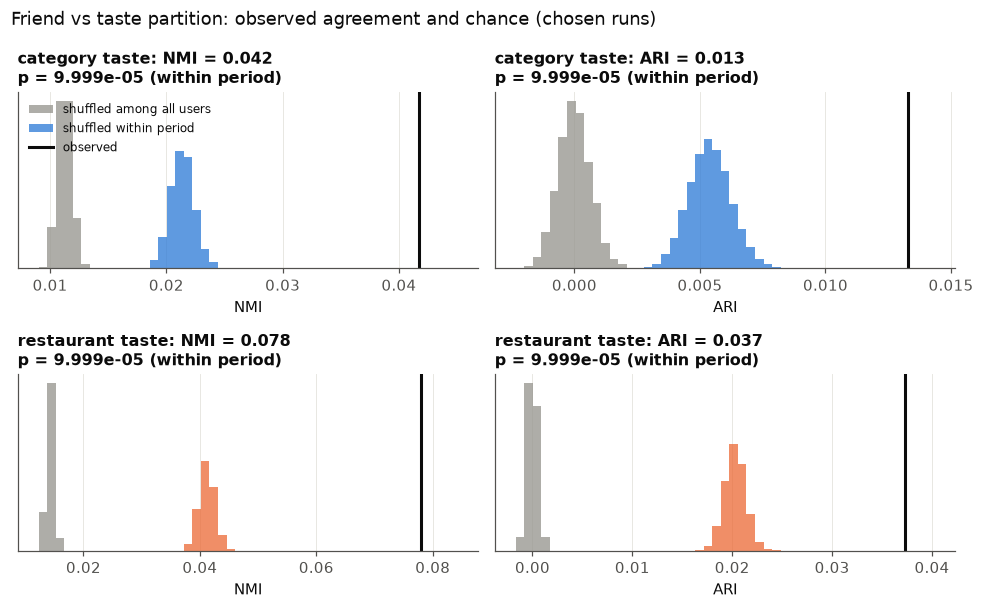

In [15]:
C.plot_main_vs_null(results, tables, FIGURES / "05_main_vs_null.png")
plt.show()

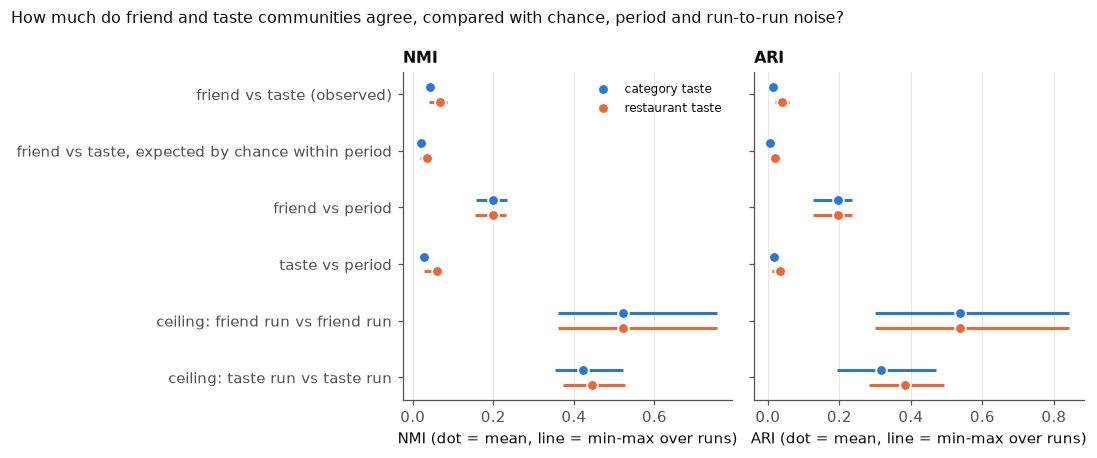

In [16]:
C.plot_agreement_levels(results, FIGURES / "05_agreement_levels.png")
plt.show()

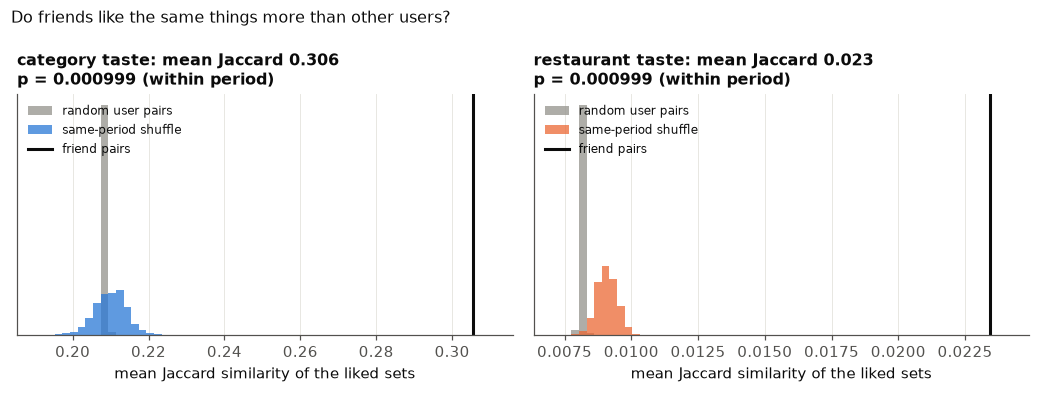

In [17]:
C.plot_pair_tests(results, pair_nulls, FIGURES / "05_pair_tests_report.png", column=True)   # one-column version for the report
plt.close()
C.plot_pair_tests(results, pair_nulls, FIGURES / "05_pair_tests.png")
plt.show()

## 7. Save

`data/results/comparison_summary.json` has every number of this notebook; the CSV files have the 20 × 20 grids and the null distributions. They are not in git: regenerate them by running this notebook.

In [18]:
results["table_v"] = C.build_table_v(results).to_dict(orient="records")
written = C.save_results(ROOT, results, tables, pair_nulls)
print("\n".join(str(p.relative_to(ROOT)) for p in written))

data/results/comparison_summary.json
data/results/comparison_grid_category.csv
data/results/comparison_main_nulls_category.csv
data/results/comparison_grid_business.csv
data/results/comparison_main_nulls_business.csv
data/results/comparison_jaccard_nulls_category.csv
data/results/comparison_jaccard_nulls_business.csv
data/results/comparison_table_v.csv


## 8. What we found

*Numbers from `data/results/comparison_summary.json` (strict run of 2026-11-25). The restaurant taste partition has 19 communities (13 real + 6 isolated singletons), the count agreed by the team; the first committed run of notebook 03 had 18. The category version has 17 (9 real + 8 singletons).*

**Short answer: friends are measurably more alike in taste than other users, but friend communities are not taste communities.**

**1. Partition level: real but small agreement.** Chosen runs, isolated users excluded:

| | NMI | chance, within period | chance, plain shuffle | ARI | chance, within period | AMI |
|---|---|---|---|---|---|---|
| category taste | 0.042 | 0.021 | 0.011 | 0.013 | 0.005 | 0.031 |
| restaurant taste | 0.078 | 0.041 | 0.014 | 0.037 | 0.020 | 0.065 |

The observed agreement is about twice the within-period chance level, with p = 1/10,001 (the smallest possible) for both measures and both versions. Controlling for the period matters: it raises the chance NMI 2 to 3 times compared with the plain shuffle, so a test without the control would have overstated the effect.

**2. Robust across runs and variants.** Over the 20 × 20 saved runs, NMI is 0.042 [0.033, 0.053] (category) and 0.067 [0.040, 0.085] (restaurant), against within-period chance means of 0.022 and 0.035. 100 % of the 400 cells beat the within-period null for NMI in both versions and for restaurant ARI. Category ARI is the weakest result: 95.75 % of the cells have p < 0.05, and the worst cell has p = 0.975. In the sensitivity variants (isolated users included, tiny communities merged or dropped) NMI stays between 0.035 and 0.043 (category) and 0.068 and 0.079 (restaurant), always with p = 0.001.

**3. Small compared with the ceiling and with the period.** Two runs of the *same* method agree far more than friends and tastes do: friend vs friend runs NMI 0.522 (ARI 0.538), taste vs taste runs NMI 0.423 / 0.445 (ARI 0.315 / 0.383). Friend–taste agreement is between about a twentieth and a fifth of that, depending on the measure and version. Friend communities are organised much more by *when* members were active than by taste: friend vs period NMI 0.200 (ARI 0.196), against taste vs period NMI 0.028 (category) and 0.059 (restaurant). So the period does not explain the taste partition, but it explains the friend partition far better than taste does.

**4. Pair level: the clearest signal.** Chosen taste partitions and liked sets, friend pairs against same-period pairs (random-pair values in brackets):

| | friend pairs | same-period pairs | random pairs |
|---|---|---|---|
| same category taste community | 0.265 | 0.150 | (0.145) |
| same restaurant taste community | 0.211 | 0.101 | (0.089) |
| mean Jaccard, liked categories | 0.306 | 0.210 | (0.209) |
| mean Jaccard, liked restaurants | 0.023 | 0.009 | (0.008) |
| share with a liked restaurant in common | 0.684 | 0.284 | (0.265) |

All p = 1/1,001 (the smallest possible). Friend pairs share a taste community 1.8 (category) to 2.1 (restaurant) times as often as same-period pairs, and their liked restaurants overlap about 2.6 times more. The pair level and the partition level tell the same story: a consistent excess over chance, small in absolute terms at the community level.

**5. Restaurants vs categories.** The two taste partitions agree only moderately with each other (NMI 0.121, ARI 0.074, 7,939 users). The restaurant version shows a stronger friend–taste link everywhere (partition, grid, pairs). Friends overlap more on *which places* they like than on *what kind of food*. That fits going out together or living in the same neighbourhood as much as similar preferences.

**Why the method behaved like this.** Agreement between two partitions is capped by how noisy each one is (run-to-run ARI 0.54 for friends, 0.32 to 0.38 for taste), and the taste partition of the category version is dominated by a few large communities (9 real communities, the 5 largest holding 80 % of the users). A modest friend–taste effect at the level of individual pairs is therefore diluted at the level of communities. Low community overlap and friends being more similar than other pairs are not in contradiction: both are what this run shows.

**Limitations.** The period control is coarse (4 bins of the median review year) and does not remove neighbourhood, going to restaurants together, or friend influence: the data cannot separate influence from homophily. Grid cells share partitions, so the share of cells with p < 0.05 is a robustness indicator, not a multiple-testing p-value.